# PET introduction: list mode and sinograms

This tutorial reconstructs a GATE simulation of an FDG brain scan on a Siemens Biograph mMR. It keeps only the true coincidences, so there are no randoms or scatter to correct for, and shows the two ways PyTomography represents PET data:

- **list mode**, one entry per detected event, giving the pair of crystals that detected it;
- **sinograms**, the same events counted in bins of angle, radial offset and axial plane.

Both are reconstructed with the same object, normalisation, attenuation and resolution model, so you can compare them directly. The [GATE tutorials](t_PETGATE_scat_sino.ipynb) then add randoms and scatter.

In [1]:
from pytomography import datasets

# The tutorial data: downloaded the first time it runs (see Tutorial data in the docs)
datasets.fetch("PET/GATE-mMR-BrainInWater")
DATA = datasets.data_dir()  # the PYTOMOGRAPHY_DATA folder, or ~/pytomography_data
# Results go here, never into the data folder
OUTPUT = datasets.output_dir("PET/GATE-mMR-BrainInWater")

PET/GATE-mMR-BrainInWater: already downloaded


In [2]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt
import pytomography
from pytomography import io
from pytomography.metadata.PET import PETSinogramPolygonProjMeta
from pytomography.projectors.PET import PETLMSystemMatrix, PETSinogramSystemMatrix
from pytomography.likelihoods import PoissonLogLikelihood
from pytomography.algorithms import OSEM
from pytomography.transforms.shared import GaussianFilter

## How much memory this needs

Set `RAM_GB` to the memory this tutorial may use, and pass it to `pytomography.set_memory_budget`. The steps that go through all 411 million crystal pairs of the scanner (the sensitivity image and the normalization sinogram) and the binning of the events then work in blocks that fit. Each reconstruction prints its estimate before it runs (`estimate_memory`). The tutorial peaks at about 16.5 GB (measured on Windows), the same with `RAM_GB = 10`, so it does not fit in 16 GB whatever `RAM_GB` is: its reconstructions hold the events, the normalization weights and whole sinograms, which the budget does not split yet. Below 10 GB the MLEM step (one subset) refuses to start. The results do not depend on the budget.

In [3]:
RAM_GB = 25 # memory (RAM) this tutorial may use, in GB (at least 10); it needs about 16.5 GB however low this is
pytomography.set_memory_budget(RAM_GB)

## 1. The scanner and the true coincidences

GATE describes the scanner in a macro file, and records every coincidence in its ROOT files: the crystals that detected the two photons, whether they came from the same decay, and whether either scattered. `io.PET.read_gate` reads both. It returns the events as pairs of crystal numbers, the object grid placed in the patient, and the projection metadata, whose `info` describes the scanner (crystal and ring counts and positions) for every PET function in PyTomography. `events='trues'` keeps only the true coincidences: unscattered photon pairs from the same decay. File 24 of the simulation is empty and adds nothing.

GATE's world has no patient in it: the dataset registry records how the phantom sat in it, and `read_gate` uses that for this dataset, so the images line up with the phantom's MR. Reading the 54 ROOT files takes a few minutes, so the first run keeps the result in `OUTPUT`.

In [4]:
path = DATA / 'PET' / 'GATE-mMR-BrainInWater'
macro = path / 'mMR_Geometry.mac'  # the scanner, as the simulation's GATE macro describes it
paths = [path / 'simple_phantom' / f'mMR_voxBrain_withSimplePhantom_{i}.root' for i in range(1, 55)]  # its 54 runs
cache = OUTPUT / 'gate_trues_norm.pt'
if not cache.exists():
    # doi: the lines of response end 9 mm inside the crystals, the mean depth of interaction. normalization: the
    # weights of section 2
    torch.save(io.PET.read_gate(paths, macro, events='trues', doi=9,
                                normalization=path / 'normalization_weights.npy'), cache)
detector_ids, object_meta, proj_meta = torch.load(cache, weights_only=False)
info = proj_meta.info
print(f"{info['NrRings']} rings of {info['NrCrystalsPerRing']} crystals, radius {info['radius']} mm")
print(f"{detector_ids.shape[0] / 1e6:.1f} million true coincidences")

64 rings of 448 crystals, radius 337.0 mm
63.3 million true coincidences


## 2. Normalisation

Crystals differ in efficiency, and some lines of response are seen more often than others because of the geometry. A scan of a thin cylindrical shell, which irradiates every line of response almost equally, measures these differences as a weight for every crystal pair. The weights come with the dataset: they were computed from such a scan (36 ROOT files, 46 GB) with its randoms left out. `read_gate` took them above (`normalization=`) and keeps them in `proj_meta.weights_sensitivity`. The pairs whose lines of response miss the calibration shell have no weight in the file (NaN); `read_gate` sets them to 0, with a warning.

In [5]:
# The weights come with the dataset. They were computed from the calibration scan (36 ROOT files, 46 GB, in
# PET/GATE-mMR-Brain/normalization_scan), randoms left out (PyTomography PR #290):
# normalization_weights = io.PET.gate_normalization(normalization_paths, info, cylinder_radius=318)
normalization_weights = proj_meta.weights_sensitivity  # one per crystal pair, in torch.combinations order
print(f"{normalization_weights.numel() / 1e6:.0f} million crystal pairs, "
      f"{int((normalization_weights == 0).sum()) / 1e6:.0f} million of them without calibration data")

411 million crystal pairs, 101 million of them without calibration data


## 3. Object space, attenuation and resolution

Both reconstructions use the same 128 × 128 × 96 grid of 2 mm voxels, centred where `read_gate` placed the scanner in the patient (`with_grid` keeps that place). The attenuation map comes from the phantom: an image in GATE's world, in cm⁻¹, which `io.PET.gate_image` places in the patient as `read_gate` placed the scanner, and `io.attenuation_map` puts on the grid in mm⁻¹. A 3 mm Gaussian blur, applied to the image before each projection, models the scanner's resolution.

In [6]:
object_meta = object_meta.with_grid(dr=(2, 2, 2), shape=(128, 128, 96))  # mm, voxels
# The phantom's attenuation map (1/cm), an image in GATE's world: gate_image places it in the patient as read_gate
# placed the scanner, and attenuation_map puts it on the grid, in 1/mm
atten_map = io.attenuation_map(io.PET.gate_image(path / 'umap_mMR_brainSimplePhantom.hv', proj_meta, units='1/cm'),
                               object_meta)
psf_transform = GaussianFilter(3.)  # mm

## 4. List-mode reconstruction

The list-mode system matrix projects the object onto the line of response of every event. Its sensitivity image, which the algorithm needs, uses the normalisation weights of every possible crystal pair: `read_gate`'s `proj_meta` holds the events, `info` and the weights.

In [7]:
system_matrix_lm = PETLMSystemMatrix(object_meta, proj_meta, obj2obj_transforms=[psf_transform],
                                     N_splits=10, attenuation_map=atten_map)
likelihood_lm = PoissonLogLikelihood(system_matrix_lm)
osem_lm = OSEM(likelihood_lm)
print(osem_lm.estimate_memory(n_subsets=14))  # its peak RAM and GPU memory, before it runs

t0 = time.time()
recon_lm = osem_lm(n_iters=4, n_subsets=14)
print(f"list mode: {time.time() - t0:.1f} s")

OSEM (PETLMSystemMatrix): 14 subsets, memory budget 25 GB
Peak ~ 9.9 GB RAM, 3.1 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 1.6 GB RAM, 0.9 GB GPU (events and their projector order 0.8 GPU, sensitivity weights 1.6 RAM, sensitivity and normalisation images (14) 0.1 GPU, image, update and attenuation map 0.03 GPU, projections (the data) 0.00 GPU)
  one subset at a time: 0.00 GB RAM, 0.9 GB GPU (expected counts, ratio and temporaries (one subset) 0.1 GPU, positions of the subset's events 0.04 GPU, building a subset's projector order (its first projection) 0.8 GPU)
  projector chunks: 0.00 GB RAM, 0.03 GB GPU (projector chunk 0.03 GPU)
  Python, CUDA, allocator: 5.1 GB RAM, 1.3 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cache (rounded and kept blocks) 0.7 GPU, memory the allocators keep (Windows) 2.1 RAM)
To use less: 28 subsets ~ 9.2 GB RAM, 2.6 GB GPU, N_splits 20 ~ 9.8 GB RAM, 

list mode: 5.2 s


## 5. Sinogram reconstruction

Binning the same events gives a sinogram whose size depends on the scanner, not on the number of events. The normalisation weights are binned the same way.

In [8]:
sinogram = io.PET.listmode_to_sinogram(detector_ids, info)
normalization_sinogram = io.PET.normalization_sinogram(normalization_weights, info)
print(f"sinogram {tuple(sinogram.shape)}: {sinogram.numel() / 1e6:.0f} million bins for {detector_ids.shape[0] / 1e6:.1f} million events")

proj_meta_sino = PETSinogramPolygonProjMeta(info)
system_matrix_sino = PETSinogramSystemMatrix(
    object_meta, proj_meta_sino,
    obj2obj_transforms=[psf_transform],
    sinogram_sensitivity=normalization_sinogram,
    attenuation_map=atten_map,
    N_splits=10,
    device='cpu')  # keep the large sinograms in host memory
likelihood_sino = PoissonLogLikelihood(system_matrix_sino, sinogram)
osem_sino = OSEM(likelihood_sino)
print(osem_sino.estimate_memory(n_subsets=14))

t0 = time.time()
recon_sino = osem_sino(n_iters=4, n_subsets=14)
print(f"sinogram: {time.time() - t0:.1f} s")

sinogram (224, 449, 4096): 412 million bins for 63.3 million events


OSEM (PETSinogramSystemMatrix): 14 subsets, memory budget 25 GB
Peak ~ 10.4 GB RAM, 1.2 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 3.3 GB RAM, 0.1 GB GPU (sensitivity sinogram 1.6 RAM, normalisation images (14) 0.1 GPU, image, update and attenuation map 0.03 GPU, projections (the data) 1.6 RAM)
  one subset at a time: 0.4 GB RAM, 0.00 GB GPU (data, expected counts, ratio and temporaries (one subset) 0.4 RAM)
  projector chunks: 0.00 GB RAM, 0.3 GB GPU (projector chunk 0.3 GPU)
  Python, CUDA, allocator: 5.5 GB RAM, 0.8 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cache (rounded and kept blocks) 0.2 GPU, memory the allocators keep (Windows) 2.4 RAM)
To use less: 28 subsets ~ 10.0 GB RAM, 1.2 GB GPU, N_splits 20 ~ 10.1 GB RAM, 1.0 GB GPU
(plus whatever else your script keeps)


sinogram: 9.7 s


## 6. Comparison

The two images look the same. Voxel by voxel they differ by a few percent, and the difference comes from the subsets, not the data: OSEM updates the image after each subset, and list mode splits the events into subsets while the sinogram splits the angles, so after four iterations the two have taken different paths.

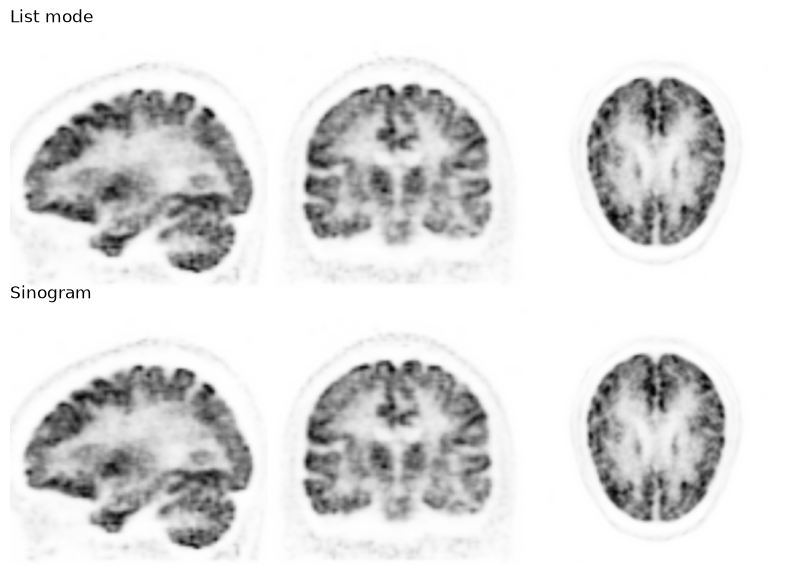

In [9]:
vmax = float(recon_lm.cpu().quantile(0.999))  # same colour scale for both
fig, axes = plt.subplots(2, 3, figsize=(10, 7), gridspec_kw={'wspace': 0.0, 'hspace': 0.05})
for row, (recon, name) in enumerate([(recon_lm, 'List mode'), (recon_sino, 'Sinogram')]):
    r = recon.cpu()
    views = [r[50, 16:-16].T, r[16:-16, 64].T, r[:, :, 48].T]  # sagittal beside the midline, coronal, axial
    for ax, image in zip(axes[row], views):
        ax.imshow(image, cmap='Greys', interpolation='gaussian', origin='lower', vmin=0, vmax=vmax)
        ax.axis('off')
    axes[row, 0].set_title(name, loc='left')
plt.show()

In [10]:
def difference(a, b):
    return 100 * float((a - b).abs().sum() / a.abs().sum())

print(f"OSEM 4 × 14: the images differ by {difference(recon_lm, recon_sino):.1f}% voxel by voxel, "
      f"and their totals by {100 * float(recon_sino.sum() / recon_lm.sum() - 1):+.2f}%")

OSEM 4 × 14: the images differ by 2.0% voxel by voxel, and their totals by +0.09%


With a single subset, OSEM is MLEM, and the two take exactly the same steps:

In [11]:
t0 = time.time()
mlem_lm = OSEM(likelihood_lm)(n_iters=40, n_subsets=1)
mlem_sino = OSEM(likelihood_sino)(n_iters=40, n_subsets=1)
print(f"MLEM, 40 iterations ({time.time() - t0:.0f} s): the images differ by {difference(mlem_lm, mlem_sino):.1f}%")

MLEM, 40 iterations (113 s): the images differ by 0.2%


## Save the images

`io.save_dicom` writes both reconstructions as DICOM PET series, one file per slice, where `object_meta` places them. GATE data have no patient frame of their own: `read_gate` placed the grid on the phantom's MR, from the dataset registry's record of where the phantom sat in GATE's world, so they line up with that NIfTI file in software that reads both, such as 3D Slicer.

In [12]:
for name, image in [('list_mode', recon_lm), ('sinogram', recon_sino)]:
    io.save_dicom(image, OUTPUT / 't_pet_introduction' / name, object_meta, series_description=f'OSEM 4x14, {name}',
                  overwrite=True)

## Next steps

- The [GATE sinogram](t_PETGATE_scat_sino.ipynb) and [list-mode](t_PETGATE_scat_lm.ipynb) tutorials reconstruct all events, estimating randoms from the delayed coincidences and scatter with single scatter simulation.
- The time-of-flight versions show how timing information sharpens the reconstruction.

In [13]:

import json, platform, torch, pytomography
def _peak_ram_gb():
    try:
        import psutil
        m = psutil.Process().memory_info()
        if hasattr(m, "peak_pagefile"):  # Windows: peak committed memory
            return round(m.peak_pagefile / 1e9, 1)
    except ImportError:
        pass
    import resource  # ru_maxrss is in kB on Linux, bytes on macOS
    return round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / (1e9 if platform.system() == "Darwin" else 1e6), 1)
_info = dict(pytomography=getattr(pytomography, "__version__", "?"), source=pytomography.__file__,
             torch=torch.__version__, python=platform.python_version(),
             gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
             peak_gpu_gb=round(torch.cuda.max_memory_allocated() / 1e9, 2) if torch.cuda.is_available() else 0.0,
             peak_ram_gb=_peak_ram_gb())
print("__PYTOMOGRAPHY_RUN__" + json.dumps(_info))


__PYTOMOGRAPHY_RUN__{"pytomography": "4.0.0rc1", "source": "C:\\Users\\lukep\\miniforge3\\envs\\pytomo-rc1\\Lib\\site-packages\\pytomography\\__init__.py", "torch": "2.14.1+cu130", "python": "3.12.16", "gpu": "NVIDIA GeForce RTX 5060 Laptop GPU", "peak_gpu_gb": 2.91, "peak_ram_gb": 16.4}
